In [ ]:
import pandas as pd
import seaborn as sns
import random as random
import matplotlib.pyplot as plt

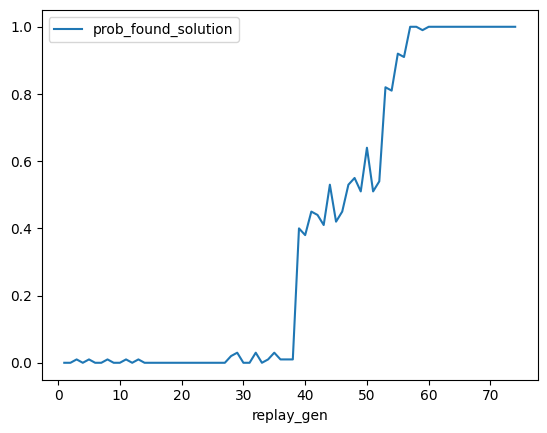

In [ ]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/FergusonAJ/gp-replays/3044792e334fdd7f1f82bb7f3f410a51b94239e7/experiments/2026_05_13_01__small_large_double_mut/hpc/data/combined_replay_data.csv"
)

# Make relevant_data dataframe to plot prob of finding soln vs replay_gen. This is data provided to orchestrator.
df["replay_gen"] = df["replay_gen"].str.extract(r"(\d+)").astype(int)
relevant_data = pd.DataFrame(
    {
        "replay_gen": df["replay_gen"],
        "prob_found_solution": df["found_solution"],
    }
)
relevant_data = relevant_data.groupby("replay_gen").mean()

sns.lineplot(relevant_data)

In [ ]:
# Players that use different strats to find del_prob_max. Inputs: gen_available = [first, last] gens you can replay from; prev_replays = df(columns = ['replay_gen', 'prob_success']). Outputs: [Is this a guess for del_prob_max, gen to run replay from] = [True/False, gen]

# Asks for all generations one by one then calculates differences and finds greatest difference
def brute_force_player_simplified(
    gen_available: list, prev_replays: pd.DataFrame
) -> list:
    gen_list = list(range(gen_available[0], gen_available[1] + 1))
    del_prob_max = [False, gen_available[0]]

    if len(prev_replays) == len(
        gen_list
    ):  # After guessing all gens to get data, find del_prob_max
        del_prob_max[0] = True
        diff = 0
        prev_prob = -1
        for index, row in prev_replays.iterrows():
            gen = row["replay_gen"]
            prob = row["prob_success"]

            if prev_prob > -1:
                if prob - prev_prob > diff:
                    diff = prob - prev_prob
                    del_prob_max[1] = int(gen)
            prev_prob = prob
    else:  # Ask for prob for next gen
        del_prob_max[1] = gen_list[len(prev_replays)]

    return del_prob_max

# Players that use different strats to find del_prob_max. Inputs: gen_available = [first, last] gens you can replay from; prev_replays = df(columns = ['replay_gen', 'outcome']). Outputs: [Is this a guess for del_prob_max, gen to run replay from] = [True/False, gen]

# Replays from each generation 10 times, then calculates the probabilities to find del_prob_max
def brute_force_player(
    gen_available: list, prev_replays: pd.DataFrame
) -> list:
    gen_list = list(range(gen_available[0], gen_available[1] + 1))
    del_prob_max = [False, gen_available[0]]

    columns = prev_replays.columns.tolist()
    replay_gen = columns[0]
    outcome = columns[1]

    if len(prev_replays) == 10 * len(
        gen_list
    ):  # After guessing all gens 10 times to get data, find del_prob_max
        del_prob_max[0] = True
        diff = 0
        prev_prob = -1
        prev_replays = prev_replays.groupby(
            replay_gen, as_index=False
        ).mean()
        for i in range(len(prev_replays)):
            gen = prev_replays.iloc[i, 0]
            prob = prev_replays.iloc[i, 1]

            if prev_prob > -1:
                if prob - prev_prob > diff:
                    diff = prob - prev_prob
                    del_prob_max[1] = int(gen)
            prev_prob = prob
    else:  # Ask for prob for next gen
        del_prob_max[1] = gen_list[len(prev_replays) % len(gen_list)]

    return del_prob_max

In [ ]:
def test_brute_force_player_simplified_first_guess():
    prev_replays = pd.DataFrame({"replay_gen": [], "prob_success": []})
    assert brute_force_player_simplified([1, 5], prev_replays) == [
        False,
        1,
    ]

def test_brute_force_player_simplified_asks_for_next():
    prev_replays = pd.DataFrame(
        {"replay_gen": [1, 2, 3], "prob_success": [0.2, 0.25, 0.8]}
    )
    assert brute_force_player_simplified([1, 5], prev_replays) == [
        False,
        4,
    ]

def test_brute_force_player_simplified_guesses_del_p():
    prev_replays = pd.DataFrame(
        {
            "replay_gen": [1, 2, 3, 4, 5],
            "prob_success": [0.2, 0.25, 0.8, 0.85, 1],
        }
    )
    assert brute_force_player_simplified([1, 5], prev_replays) == [True, 3]

def test_brute_force_player_asks_for_next_gen():
    prev_replays = pd.DataFrame({"replay_gen": [1], "outcome": [1]})
    assert brute_force_player([1, 5], prev_replays) == [False, 2]

def test_brute_force_player_cycles_middle():
    prev_replays = pd.DataFrame(
        {"replay_gen": [1, 2, 1, 2, 1, 2], "outcome": [1, 1, 0, 0, 0, 1]}
    )
    assert brute_force_player([1, 2], prev_replays) == [False, 1]

def test_brute_force_player_cycles_end():
    prev_replays = pd.DataFrame(
        {
            "replay_gen": [
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
            ],
            "outcome": [
                1,
                1,
                0,
                0,
                0,
                1,
                1,
                1,
                0,
                0,
                0,
                1,
                1,
                1,
                0,
                0,
                0,
                1,
            ],
        }
    )
    assert brute_force_player([1, 2], prev_replays) == [False, 1]

def test_brute_force_player_finds_del_prob():
    replay_gens = []
    outcomes = []
    for i in range(30):
        if i % 3 != 0:
            replay_gens.append(i % 3)
        else:
            replay_gens.append(3)
        random.seed(i * 99)
        outcomes.append(random.randint(0, 1))

    print(replay_gens)

    prev_replays = pd.DataFrame(
        {"replay_gen": replay_gens, "outcome": outcomes}
    )

    assert brute_force_player([1, 3], prev_replays) == [True, 3]

.......                                                                  [100%]
=================================== Overview ===================================
Passed Tests:
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_asks_for_next_gen
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_cycles_end
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_cycles_middle
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_finds_del_prob
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_simplified_asks_for_next
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_simplified_first_guess
✓ bindle/2026-11-04-replay_game.py::test_brute_force_player_simplified_guesses_del_p

Summary:
Total: 7, Passed: 7, Failed: 0, Errors: 0, Skipped: 0


In [ ]:
replay_gen = []
outcome = []
for i in range(30):
    if i % 3 != 0:
        replay_gen.append(i % 3)
    else:
        replay_gen.append(3)
    random.seed(i * 99)
    outcome.append(random.randint(0, 1))

prev_replays = pd.DataFrame({"replay_gen": replay_gen, "outcome": outcome})

prev_replays_probs = prev_replays.groupby("replay_gen").mean()
max_prob = prev_replays_probs["outcome"].idxmax()
# print(max_prob)
prev_replays

,replay_gen,outcome
0,3,1
1,1,1
2,2,0
3,3,1
4,1,0
...,...,...
25,1,0
26,2,0
27,3,0
28,1,1


In [ ]:
# Orchestrators: They are provided the data and the player, and return prev_replays to the player until the player guesses del_prob_max.

# This is the simple version in which the player guesses the gen and the orchestrator replays 100 times and returns the probability of that gen being successful.

def replay_100_return_prob(
    dataset: pd.DataFrame, player: list
) -> pd.DataFrame:
    prev_replays = pd.DataFrame({"replay_gen": [], "prob_success": []})

    columns = dataset.columns.tolist()
    replay_gen = columns[0]
    prob_found_solution = columns[1]

    request = player(
        [dataset[replay_gen].iloc[0], dataset[replay_gen].iloc[-1]],
        prev_replays,
    )

    while (
        request[0] == False
    ):  # Give it the prob if it's not guessing del_prob_max
        gen = request[1]
        prob_success = dataset.loc[
            dataset[replay_gen] == gen, prob_found_solution
        ].iloc[0]
        prev_replays.loc[len(prev_replays)] = [gen, prob_success]
        request = player(
            [dataset[replay_gen].iloc[0], dataset[replay_gen].iloc[-1]],
            prev_replays,
        )

    gen = request[1]
    prob_success = dataset.loc[
        dataset[replay_gen] == gen, prob_found_solution
    ].iloc[0]
    prev_replays.loc[len(prev_replays)] = [gen, prob_success]
    prev_replays["replay_gen"] = prev_replays["replay_gen"].astype(int)

    return prev_replays

# This orchestrator only replays once, and returns whether the replay gave a success or fail (0 or 1)

def one_replay_per_call(
    dataset: pd.DataFrame, player: list
) -> pd.DataFrame:
    prev_replays = pd.DataFrame({"replay_gen": [], "outcome": []})

    # Column names
    columns = dataset.columns.tolist()
    replay_gen = columns[0]
    found_solution = columns[1]

    request = player(
        [dataset[replay_gen].iloc[0], dataset[replay_gen].iloc[-1]],
        prev_replays,
    )

    gen = request[1]

    while (
        request[0] == False
    ):  # Give it the outcome if it's not guessing del_prob_max
        gen = request[1]
        prob_success = dataset.loc[
            dataset[replay_gen] == gen, found_solution
        ].iloc[0]
        seed = gen * len(prev_replays)
        random.seed(seed)
        if random.random() < prob_success:
            prev_replays.loc[len(prev_replays)] = [gen, 1]
        else:
            prev_replays.loc[len(prev_replays)] = [gen, 0]

        request = player(
            [dataset[replay_gen].iloc[0], dataset[replay_gen].iloc[-1]],
            prev_replays,
        )

    gen = request[1]
    prob_success = dataset.loc[
        dataset[replay_gen] == gen, found_solution
    ].iloc[0]
    seed = int(gen * len(prev_replays))
    random.seed(seed)
    if random.random() < prob_success:
        prev_replays.loc[len(prev_replays)] = [gen, 1]
    else:
        prev_replays.loc[len(prev_replays)] = [gen, 0]

    prev_replays["replay_gen"] = prev_replays["replay_gen"].astype(int)

    return prev_replays

In [ ]:
def test_replay_100_return_prob_first_last_call():
    player = brute_force_player_simplified
    data = pd.DataFrame({"replay_gen": [1], "found_solution": [0.2]})
    output = pd.DataFrame(
        {"replay_gen": [1, 1], "prob_success": [0.2, 0.2]}
    )
    pd.testing.assert_frame_equal(
        replay_100_return_prob(data, player), output
    )

def test_one_replay_per_call_first_last_call():
    player = brute_force_player
    data = pd.DataFrame({"replay_gen": [1], "prob_found_solution": [1]})
    output = pd.DataFrame(
        {
            "replay_gen": [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            "outcome": [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        }
    )
    pd.testing.assert_frame_equal(
        one_replay_per_call(data, player), output
    )

def test_one_replay_per_call_diff_probs_each_run():
    player = brute_force_player
    data = pd.DataFrame(
        {"replay_gen": [1, 2], "prob_found_solution": [0, 1]}
    )
    output = pd.DataFrame(
        {
            "replay_gen": [
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                1,
                2,
                2,
            ],
            "outcome": [
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                0,
                1,
                1,
            ],
        }
    )
    pd.testing.assert_frame_equal(
        one_replay_per_call(data, player), output
    )

...                                                                      [100%]
=================================== Overview ===================================
Passed Tests:
✓ bindle/2026-11-04-replay_game.py::test_one_replay_per_call_diff_probs_each_run
✓ bindle/2026-11-04-replay_game.py::test_one_replay_per_call_first_last_call
✓ bindle/2026-11-04-replay_game.py::test_replay_100_return_prob_first_last_call

Summary:
Total: 3, Passed: 3, Failed: 0, Errors: 0, Skipped: 0


In [ ]:
random.seed(524288)
random.random()

0.5345784730563261

In [ ]:
# Evaluation system, then other player

def evaluator(player_list, orchestrator):
    return player_data